Імпорт бібліотек та налаштування GPU

In [ ]:
import os
import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import fetch_20newsgroups

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

# Фіксація seed для відтворюваності результатів
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Використовується пристрій: {device}")

Використовується пристрій: cuda


Повнозв'язані нейронні мережі (MLP) на табличних даних

In [ ]:
# Завантаження датасету
df = pd.read_csv('Obfuscated-MalMem2022.csv')
print("Розмір датасету:", df.shape)
print(df[['Category', 'Class']].head())

TARGET_COL = 'Class'

# Видаляємо обидві цільові колонки з ознак
X = df.drop(columns=['Category', 'Class'], errors='ignore')
X = X.select_dtypes(include=[np.number]).fillna(0)

le = LabelEncoder()
y = le.fit_transform(df[TARGET_COL])
num_classes = len(le.classes_)
print(f"Класи ({num_classes}): {le.classes_}")

# Розбиття на train (70%), val (15%), test (15%) зі стратифікацією
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

# Стандартизація ознак
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Створення DataLoader
BATCH_SIZE = 128

train_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
val_dataset = TensorDataset(torch.tensor(X_val_scaled, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Розмір датасету: (58596, 57)
  Category   Class
0   Benign  Benign
1   Benign  Benign
2   Benign  Benign
3   Benign  Benign
4   Benign  Benign
Класи (2): ['Benign' 'Malware']


Архітектура MLP, навчання та візуалізація Learning Curves

Epoch [1/25] | Train Loss: 0.0365, Acc: 0.9916 | Val Loss: 0.0044, Acc: 0.9989
Epoch [5/25] | Train Loss: 0.0025, Acc: 0.9993 | Val Loss: 0.0008, Acc: 0.9998
Epoch [10/25] | Train Loss: 0.0023, Acc: 0.9993 | Val Loss: 0.0006, Acc: 0.9998
Epoch [15/25] | Train Loss: 0.0011, Acc: 0.9997 | Val Loss: 0.0009, Acc: 0.9999
Epoch [20/25] | Train Loss: 0.0015, Acc: 0.9996 | Val Loss: 0.0005, Acc: 0.9998
Epoch [25/25] | Train Loss: 0.0013, Acc: 0.9996 | Val Loss: 0.0003, Acc: 0.9999


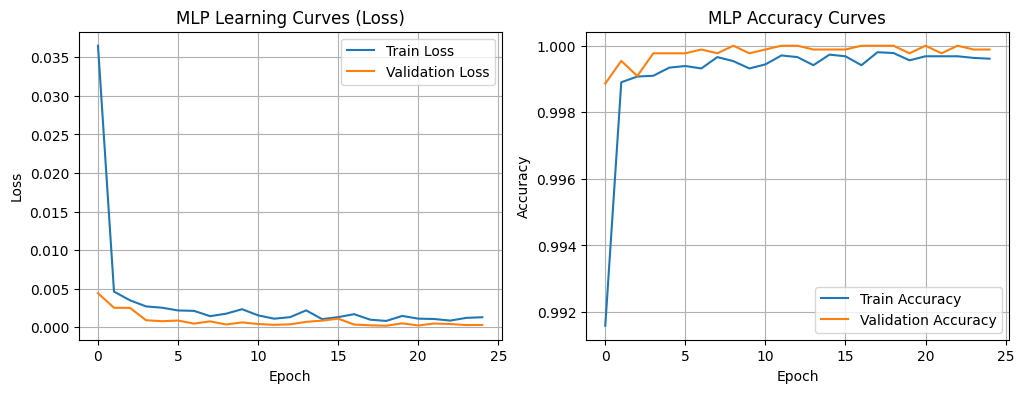

In [ ]:
class TabularMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.net(x)

mlp_model = TabularMLP(X_train_scaled.shape[1], num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)

EPOCHS = 25
history_mlp = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(EPOCHS):
    mlp_model.train()
    train_loss, correct, total = 0.0, 0, 0
    for X_b, y_b in train_loader:
        X_b, y_b = X_b.to(device), y_b.to(device)
        optimizer.zero_grad()
        outputs = mlp_model(X_b)
        loss = criterion(outputs, y_b)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * X_b.size(0)
        correct += (outputs.argmax(1) == y_b).sum().item()
        total += y_b.size(0)

    train_loss /= total
    train_acc = correct / total

    # Валідація
    mlp_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for X_b, y_b in val_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            outputs = mlp_model(X_b)
            loss = criterion(outputs, y_b)
            val_loss += loss.item() * X_b.size(0)
            val_correct += (outputs.argmax(1) == y_b).sum().item()
            val_total += y_b.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    history_mlp['train_loss'].append(train_loss)
    history_mlp['val_loss'].append(val_loss)
    history_mlp['train_acc'].append(train_acc)
    history_mlp['val_acc'].append(val_acc)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}] | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")

# Побудова Learning Curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_mlp['train_loss'], label='Train Loss')
ax[0].plot(history_mlp['val_loss'], label='Validation Loss')
ax[0].set_title('MLP Learning Curves (Loss)')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(history_mlp['train_acc'], label='Train Accuracy')
ax[1].plot(history_mlp['val_acc'], label='Validation Accuracy')
ax[1].set_title('MLP Accuracy Curves')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[1].grid(True)
plt.show()

Оцінка на тесті та порівняння з класичним ML (Random Forest з Lab 1)

In [ ]:
# Оцінка MLP на тестовій вибірці
mlp_model.eval()
y_pred_mlp = []
with torch.no_grad():
    for X_b, _ in test_loader:
        X_b = X_b.to(device)
        preds = mlp_model(X_b).argmax(1).cpu().numpy()
        y_pred_mlp.extend(preds)

mlp_acc = accuracy_score(y_test, y_pred_mlp)
mlp_f1 = f1_score(y_test, y_pred_mlp, average='weighted')

# Базова класична модель для швидкого порівняння
rf_clf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_clf.fit(X_train_scaled, y_train)
y_pred_rf = rf_clf.predict(X_test_scaled)
rf_acc = accuracy_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf, average='weighted')

print("=== Звіт класифікації MLP (Test) ===")
print(classification_report(y_test, y_pred_mlp, target_names=le.classes_, digits=4))

comparison_df1 = pd.DataFrame({
    'Модель': ['Random Forest (Lab 1)', 'MLP (PyTorch)'],
    'Test Accuracy': [rf_acc, mlp_acc],
    'Test F1-score (weighted)': [rf_f1, mlp_f1]
})
print("\nПорівняльна таблиця:")
print(comparison_df1.to_string(index=False))

=== Звіт класифікації MLP (Test) ===
              precision    recall  f1-score   support

      Benign     1.0000    0.9993    0.9997      4395
     Malware     0.9993    1.0000    0.9997      4395

    accuracy                         0.9997      8790
   macro avg     0.9997    0.9997    0.9997      8790
weighted avg     0.9997    0.9997    0.9997      8790


Порівняльна таблиця:
               Модель  Test Accuracy  Test F1-score (weighted)
Random Forest (Lab 1)       0.999886                  0.999886
        MLP (PyTorch)       0.999659                  0.999659


Висновок: Обидва підходи мають майже ідеальну якість бінарної класифікації (~99.97–99.99%), оскільки датасет добре розділяють класи. Random Forest показує кращі результати на соті частки відсотка і не потребує попереднього масштабування ознак, проте правильно регуляризований MLP практично не поступається йому в точності

Завдання 2. Згорткові нейронні мережі (CNN)

\Завантаження датасету зображень, опис та візуалізація

100%|██████████| 94.3M/94.3M [00:00<00:00, 107MB/s]


Датасет: EuroSAT
Загальна кількість зображень: 27000
Кількість класів: 10
Назви класів: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


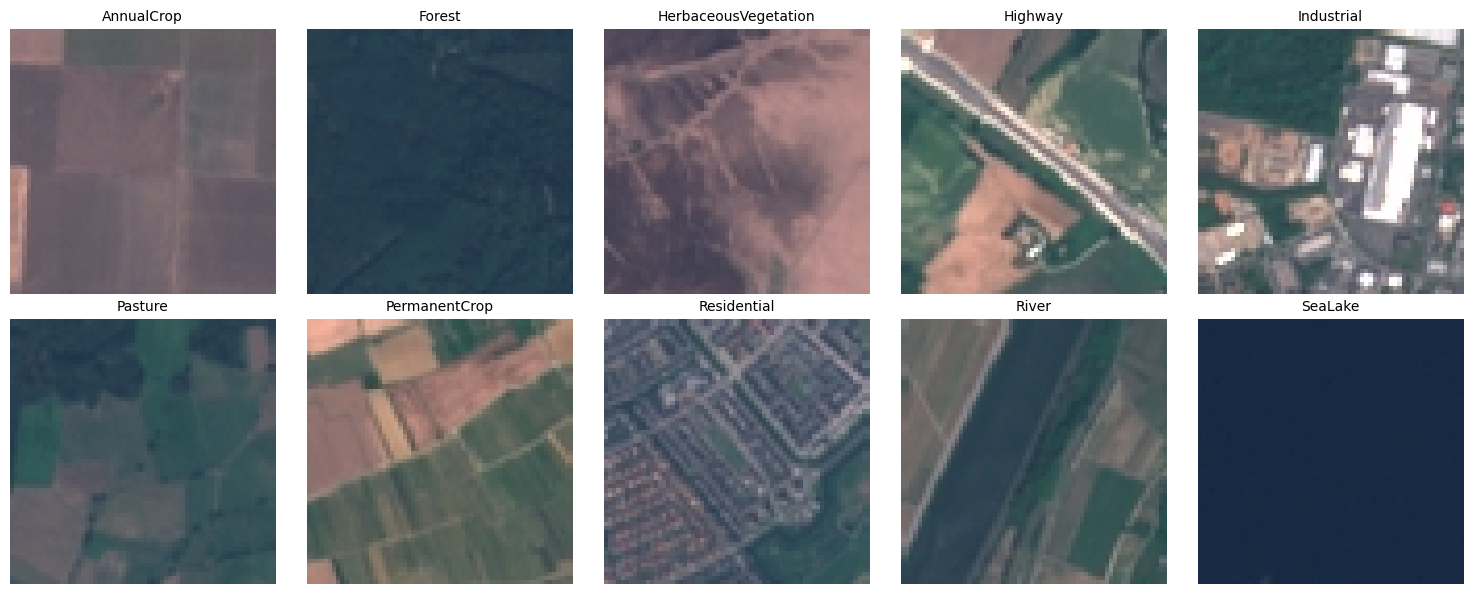

In [ ]:
# Завантаження EuroSAT
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

IMG_SIZE = 64

transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_eval = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = torchvision.datasets.EuroSAT(root='./data', download=True, transform=transform_train)
class_names_img = full_dataset.classes
num_img_classes = len(class_names_img)

print(f"Датасет: EuroSAT")
print(f"Загальна кількість зображень: {len(full_dataset)}")
print(f"Кількість класів: {num_img_classes}")
print(f"Назви класів: {class_names_img}")

# Візуалізація по 1 прикладу для кожного класу
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
shown_classes = set()

inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

for img, label in full_dataset:
    if label not in shown_classes:
        ax = axes[label]
        img_vis = torch.clamp(inv_normalize(img), 0, 1).permute(1, 2, 0).numpy()
        ax.imshow(img_vis)
        ax.set_title(class_names_img[label], fontsize=10)
        ax.axis('off')
        shown_classes.add(label)
    if len(shown_classes) == num_img_classes:
        break
plt.tight_layout()
plt.show()

# Для швидкого навчання в Colab беру підмножину 8000 зображень
subset_indices = np.random.choice(len(full_dataset), size=8000, replace=False)
train_idx, temp_idx = train_test_split(subset_indices, test_size=0.3, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=SEED)

# Окремі об'єкти датасету без аугментації для val/test
eval_dataset_base = torchvision.datasets.EuroSAT(root='./data', download=False, transform=transform_eval)

train_img_loader = DataLoader(torch.utils.data.Subset(full_dataset, train_idx), batch_size=64, shuffle=True, num_workers=2)
val_img_loader = DataLoader(torch.utils.data.Subset(eval_dataset_base, val_idx), batch_size=64, shuffle=False, num_workers=2)
test_img_loader = DataLoader(torch.utils.data.Subset(eval_dataset_base, test_idx), batch_size=64, shuffle=False, num_workers=2)

Використано набір супутникових знімків EuroSAT (27 000 RGB-зображень розміром $64 \times 64$, розподілених на 10 класів ландшафтів

Проста CNN з нуля (а) та Pretrained ResNet18 (б)

In [ ]:
# Універсальна функція навчання для зображень
def train_image_model(model, train_loader, val_loader, epochs=10, lr=1e-3, model_name="Model"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        t_loss, t_corr, t_tot = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()

            t_loss += loss.item() * imgs.size(0)
            t_corr += (out.argmax(1) == labels).sum().item()
            t_tot += labels.size(0)

        model.eval()
        v_loss, v_corr, v_tot = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                out = model(imgs)
                loss = criterion(out, labels)
                v_loss += loss.item() * imgs.size(0)
                v_corr += (out.argmax(1) == labels).sum().item()
                v_tot += labels.size(0)

        history['train_loss'].append(t_loss / t_tot)
        history['val_loss'].append(v_loss / v_tot)
        history['train_acc'].append(t_corr / t_tot)
        history['val_acc'].append(v_corr / v_tot)

        print(f"[{model_name}] Epoch {epoch+1}/{epochs} | Train Loss: {t_loss/t_tot:.4f}, Acc: {t_corr/t_tot:.4f} | Val Loss: {v_loss/v_tot:.4f}, Acc: {v_corr/v_tot:.4f}")

    elapsed = time.time() - start_time
    print(f"Час навчання {model_name}: {elapsed:.1f} сек.\n")
    return model, history, elapsed

# 2а) Власна проста CNN (3 згорткові шари + FC)
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2), # 32x32

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2), # 16x16

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)  # 8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn_scratch = SimpleCNN(num_img_classes)
cnn_scratch, hist_cnn, time_cnn = train_image_model(cnn_scratch, train_img_loader, val_img_loader, epochs=12, lr=1e-3, model_name="SimpleCNN")

# 2б) Pretrained ResNet18 (Transfer Learning)
resnet_pretrained = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
# Заміна вихідного класифікатора під кількість класів датасету
resnet_pretrained.fc = nn.Linear(resnet_pretrained.fc.in_features, num_img_classes)

resnet_pretrained, hist_resnet, time_resnet = train_image_model(resnet_pretrained, train_img_loader, val_img_loader, epochs=12, lr=3e-4, model_name="ResNet18")

[SimpleCNN] Epoch 1/12 | Train Loss: 1.6364, Acc: 0.4445 | Val Loss: 1.2386, Acc: 0.5325
[SimpleCNN] Epoch 2/12 | Train Loss: 1.0229, Acc: 0.6284 | Val Loss: 0.9208, Acc: 0.6733
[SimpleCNN] Epoch 3/12 | Train Loss: 0.9042, Acc: 0.6784 | Val Loss: 1.0285, Acc: 0.6275
[SimpleCNN] Epoch 4/12 | Train Loss: 0.8285, Acc: 0.7059 | Val Loss: 0.6525, Acc: 0.7783
[SimpleCNN] Epoch 5/12 | Train Loss: 0.7259, Acc: 0.7484 | Val Loss: 0.6819, Acc: 0.7567
[SimpleCNN] Epoch 6/12 | Train Loss: 0.7018, Acc: 0.7489 | Val Loss: 0.6378, Acc: 0.7750
[SimpleCNN] Epoch 7/12 | Train Loss: 0.6781, Acc: 0.7575 | Val Loss: 0.6696, Acc: 0.7525
[SimpleCNN] Epoch 8/12 | Train Loss: 0.6283, Acc: 0.7779 | Val Loss: 0.4991, Acc: 0.8208
[SimpleCNN] Epoch 9/12 | Train Loss: 0.5982, Acc: 0.7930 | Val Loss: 0.6644, Acc: 0.7617
[SimpleCNN] Epoch 10/12 | Train Loss: 0.5985, Acc: 0.7963 | Val Loss: 0.6263, Acc: 0.7800
[SimpleCNN] Epoch 11/12 | Train Loss: 0.5754, Acc: 0.7987 | Val Loss: 0.5120, Acc: 0.8217
[SimpleCNN] Epoch 1

100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


[ResNet18] Epoch 1/12 | Train Loss: 0.4583, Acc: 0.8546 | Val Loss: 0.2612, Acc: 0.9158
[ResNet18] Epoch 2/12 | Train Loss: 0.1612, Acc: 0.9480 | Val Loss: 0.1993, Acc: 0.9375
[ResNet18] Epoch 3/12 | Train Loss: 0.1295, Acc: 0.9584 | Val Loss: 0.2060, Acc: 0.9383
[ResNet18] Epoch 4/12 | Train Loss: 0.1038, Acc: 0.9661 | Val Loss: 0.2103, Acc: 0.9350
[ResNet18] Epoch 5/12 | Train Loss: 0.1005, Acc: 0.9671 | Val Loss: 0.2516, Acc: 0.9308
[ResNet18] Epoch 6/12 | Train Loss: 0.0771, Acc: 0.9743 | Val Loss: 0.1987, Acc: 0.9350
[ResNet18] Epoch 7/12 | Train Loss: 0.0554, Acc: 0.9841 | Val Loss: 0.2219, Acc: 0.9408
[ResNet18] Epoch 8/12 | Train Loss: 0.0700, Acc: 0.9770 | Val Loss: 0.2186, Acc: 0.9300
[ResNet18] Epoch 9/12 | Train Loss: 0.0773, Acc: 0.9775 | Val Loss: 0.2327, Acc: 0.9408
[ResNet18] Epoch 10/12 | Train Loss: 0.0596, Acc: 0.9820 | Val Loss: 0.2107, Acc: 0.9433
[ResNet18] Epoch 11/12 | Train Loss: 0.0472, Acc: 0.9854 | Val Loss: 0.1450, Acc: 0.9550
[ResNet18] Epoch 12/12 | Train

ResNet18 вже після 1-ї епохи досягає Val Accuracy = 91.58% (Val Loss = 0.2612), тоді як SimpleCNN стартує з 53.25% (Val Loss = 1.2386)


Порівняння Learning Curves та тест CNN vs Pretrained ResNet18

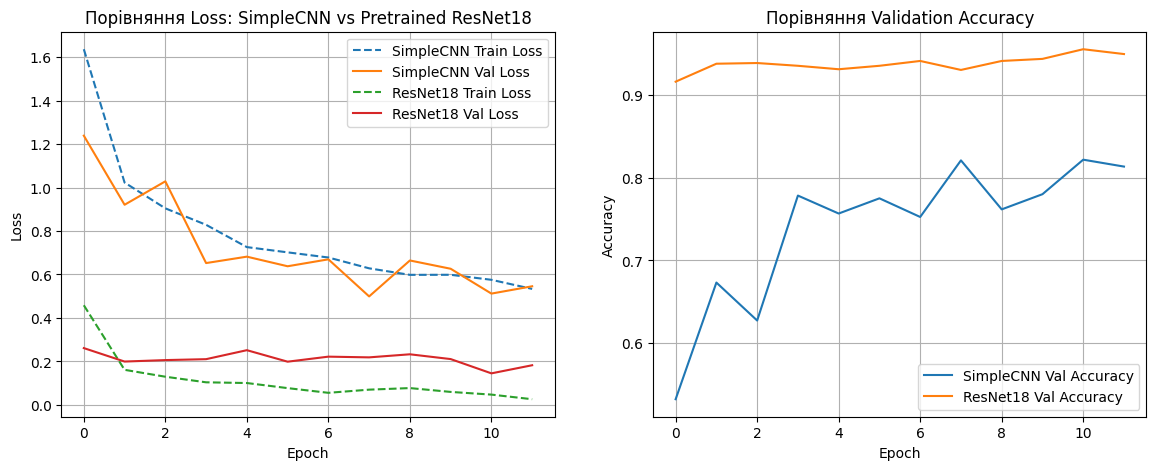

               Модель  Test Accuracy  Test F1-score  Час навчання (сек)
   SimpleCNN (з нуля)       0.797500       0.793928                66.4
ResNet18 (Pretrained)       0.950833       0.950750                62.2


In [ ]:
# Візуалізація кривих навчання для обох моделей
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(hist_cnn['train_loss'], '--', label='SimpleCNN Train Loss')
ax[0].plot(hist_cnn['val_loss'], label='SimpleCNN Val Loss')
ax[0].plot(hist_resnet['train_loss'], '--', label='ResNet18 Train Loss')
ax[0].plot(hist_resnet['val_loss'], label='ResNet18 Val Loss')
ax[0].set_title('Порівняння Loss: SimpleCNN vs Pretrained ResNet18')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(hist_cnn['val_acc'], label='SimpleCNN Val Accuracy')
ax[1].plot(hist_resnet['val_acc'], label='ResNet18 Val Accuracy')
ax[1].set_title('Порівняння Validation Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[1].grid(True)
plt.show()

# Оцінка на тестовій вибірці
def evaluate_img_model(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            preds.extend(model(imgs).argmax(1).cpu().numpy())
            targets.extend(labels.numpy())
    return accuracy_score(targets, preds), f1_score(targets, preds, average='weighted')

acc_cnn, f1_cnn = evaluate_img_model(cnn_scratch, test_img_loader)
acc_res, f1_res = evaluate_img_model(resnet_pretrained, test_img_loader)

comparison_df2 = pd.DataFrame({
    'Модель': ['SimpleCNN (з нуля)', 'ResNet18 (Pretrained)'],
    'Test Accuracy': [acc_cnn, acc_res],
    'Test F1-score': [f1_cnn, f1_res],
    'Час навчання (сек)': [round(time_cnn, 1), round(time_resnet, 1)]
})
print(comparison_df2.to_string(index=False))

Висновки: при  обмеженому датасеті у 5600 зображень, ResNet18 вже має натреновані на ImageNet згорткові фільтри для виділення текстур, контурів і геометричних форм, тому їй достатньо лише адаптувати верхні шари, тоді як SimpleCNN змушена вчити всі фільтри з нуля

Завдання 3. Нейронні мережі для класифікації текстів

Передобробка текстів (токенізація, словник, індексація, padding/truncation)

In [ ]:
categories = ['comp.graphics', 'sci.crypt', 'sci.space']

# Завантаження даних (видаляємо заголовки та підпис)
train_news = fetch_20newsgroups(subset='train', categories=categories, remove=('headers', 'footers', 'quotes'), random_state=SEED)
test_news = fetch_20newsgroups(subset='test', categories=categories, remove=('headers', 'footers', 'quotes'), random_state=SEED)

# Розбиваємо train на train (85%) та validation (15%)
X_txt_train, X_txt_val, y_txt_train, y_txt_val = train_test_split(
    train_news.data, train_news.target, test_size=0.15, random_state=SEED, stratify=train_news.target
)
X_txt_test, y_txt_test = test_news.data, test_news.target

print(f"Кількість текстів -> Train: {len(X_txt_train)}, Val: {len(X_txt_val)}, Test: {len(X_txt_test)}")

# Функція токенізації
def tokenize(text):
    text = text.lower()
    return re.findall(r'\b[a-z]{2,}\b', text)

# Побудова словника на основі train вибірки
MAX_VOCAB_SIZE = 15000
MAX_SEQ_LEN = 200

counter = Counter()
for text in X_txt_train:
    counter.update(tokenize(text))

# Спеціальні токени: <PAD> = 0, <UNK> = 1
vocab = {'<PAD>': 0, '<UNK>': 1}
for idx, (word, _) in enumerate(counter.most_common(MAX_VOCAB_SIZE - 2), start=2):
    vocab[word] = idx

print(f"Розмір словника: {len(vocab)}")

# Перетворення токенів в індекси + padding / truncation
def encode_and_pad(texts, vocab, max_len):
    encoded = np.zeros((len(texts), max_len), dtype=np.int64)
    for i, text in enumerate(texts):
        tokens = tokenize(text)[:max_len] # truncation
        ids = [vocab.get(t, 1) for t in tokens]
        encoded[i, :len(ids)] = ids # padding нулями праворуч
    return encoded

X_train_idx = encode_and_pad(X_txt_train, vocab, MAX_SEQ_LEN)
X_val_idx = encode_and_pad(X_txt_val, vocab, MAX_SEQ_LEN)
X_test_idx = encode_and_pad(X_txt_test, vocab, MAX_SEQ_LEN)

train_txt_loader = DataLoader(TensorDataset(torch.tensor(X_train_idx), torch.tensor(y_txt_train, dtype=torch.long)), batch_size=64, shuffle=True)
val_txt_loader = DataLoader(TensorDataset(torch.tensor(X_val_idx), torch.tensor(y_txt_val, dtype=torch.long)), batch_size=64, shuffle=False)
test_txt_loader = DataLoader(TensorDataset(torch.tensor(X_test_idx), torch.tensor(y_txt_test, dtype=torch.long)), batch_size=64, shuffle=False)

Кількість текстів -> Train: 1506, Val: 266, Test: 1179
Розмір словника: 15000


Завантаження Pretrained Embeddings (GloVe 100d)

In [ ]:
!pip install -q gensim
import gensim.downloader as api

print("Завантаження GloVe (100d) через gensim...")
glove_model = api.load("glove-wiki-gigaword-100")

EMBED_DIM = 100
embedding_matrix = np.random.normal(scale=0.6, size=(len(vocab), EMBED_DIM))
embedding_matrix[0] = np.zeros(EMBED_DIM)  # Вектор для <PAD> нульовий

found_words = 0
for word, idx in vocab.items():
    if word in glove_model:
        embedding_matrix[idx] = glove_model[word]
        found_words += 1

print(f"Знайдено слів у GloVe: {found_words} з {len(vocab)} ({found_words/len(vocab)*100:.1f}%)")
pretrained_weights = torch.tensor(embedding_matrix, dtype=torch.float32)

Завантаження GloVe (100d) через gensim...
[==================================================] 100.0% 128.1/128.1MB downloaded
Знайдено слів у GloVe: 13177 з 15000 (87.8%)


Модель BiLSTM (а: випадкові ваги vs б: GloVe embeddings)

In [ ]:
class TextBiLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, pretrained_embeddings=None, freeze_emb=False):
        super().__init__()
        if pretrained_embeddings is not None:
            self.embedding = nn.Embedding.from_pretrained(pretrained_embeddings, freeze=freeze_emb, padding_idx=0)
        else:
            self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        emb = self.dropout(self.embedding(x))
        lstm_out, _ = self.lstm(emb)
        pooled = torch.mean(lstm_out, dim=1)
        return self.fc(self.dropout(pooled))

def train_text_model(model, train_loader, val_loader, epochs=15, lr=1e-3, model_name="LSTM"):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        t_loss, t_corr, t_tot = 0.0, 0, 0
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            out = model(x_b)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()

            t_loss += loss.item() * x_b.size(0)
            t_corr += (out.argmax(1) == y_b).sum().item()
            t_tot += y_b.size(0)

        model.eval()
        v_loss, v_corr, v_tot = 0.0, 0, 0
        with torch.no_grad():
            for x_b, y_b in val_loader:
                x_b, y_b = x_b.to(device), y_b.to(device)
                out = model(x_b)
                loss = criterion(out, y_b)
                v_loss += loss.item() * x_b.size(0)
                v_corr += (out.argmax(1) == y_b).sum().item()
                v_tot += y_b.size(0)

        history['train_loss'].append(t_loss / t_tot)
        history['val_loss'].append(v_loss / v_tot)
        history['train_acc'].append(t_corr / t_tot)
        history['val_acc'].append(v_corr / v_tot)

        if (epoch + 1) % 3 == 0 or epoch == 0:
            print(f"[{model_name}] Epoch {epoch+1}/{epochs} | Train Loss: {t_loss/t_tot:.4f}, Acc: {t_corr/t_tot:.4f} | Val Loss: {v_loss/v_tot:.4f}, Acc: {v_corr/v_tot:.4f}")

    elapsed = time.time() - start_time
    return model, history, elapsed

# 3а) BiLSTM з випадковою ініціалізацією Embedding layer
lstm_random = TextBiLSTM(len(vocab), EMBED_DIM, hidden_dim=64, num_classes=len(categories), pretrained_embeddings=None)
lstm_random, hist_txt_rand, time_txt_rand = train_text_model(lstm_random, train_txt_loader, val_txt_loader, epochs=15, lr=1e-3, model_name="BiLSTM (Random)")

# 3б) BiLSTM з Pretrained GloVe Embeddings
lstm_glove = TextBiLSTM(len(vocab), EMBED_DIM, hidden_dim=64, num_classes=len(categories), pretrained_embeddings=pretrained_weights, freeze_emb=False)
lstm_glove, hist_txt_glove, time_txt_glove = train_text_model(lstm_glove, train_txt_loader, val_txt_loader, epochs=15, lr=1e-3, model_name="BiLSTM (GloVe)")

[BiLSTM (Random)] Epoch 1/15 | Train Loss: 1.0903, Acc: 0.3732 | Val Loss: 1.0655, Acc: 0.4887
[BiLSTM (Random)] Epoch 3/15 | Train Loss: 1.0353, Acc: 0.4675 | Val Loss: 0.9886, Acc: 0.5150
[BiLSTM (Random)] Epoch 6/15 | Train Loss: 0.8325, Acc: 0.6328 | Val Loss: 0.8735, Acc: 0.5902
[BiLSTM (Random)] Epoch 9/15 | Train Loss: 0.6556, Acc: 0.7384 | Val Loss: 0.9303, Acc: 0.6504
[BiLSTM (Random)] Epoch 12/15 | Train Loss: 0.5214, Acc: 0.8147 | Val Loss: 0.6297, Acc: 0.7669
[BiLSTM (Random)] Epoch 15/15 | Train Loss: 0.4425, Acc: 0.8293 | Val Loss: 0.7600, Acc: 0.7293
[BiLSTM (GloVe)] Epoch 1/15 | Train Loss: 1.0667, Acc: 0.4343 | Val Loss: 1.0376, Acc: 0.4474
[BiLSTM (GloVe)] Epoch 3/15 | Train Loss: 0.7937, Acc: 0.6733 | Val Loss: 0.7785, Acc: 0.6955
[BiLSTM (GloVe)] Epoch 6/15 | Train Loss: 0.5358, Acc: 0.8074 | Val Loss: 0.5001, Acc: 0.8308
[BiLSTM (GloVe)] Epoch 9/15 | Train Loss: 0.3749, Acc: 0.8632 | Val Loss: 0.5324, Acc: 0.8195
[BiLSTM (GloVe)] Epoch 12/15 | Train Loss: 0.2685, A

Графіки Learning Curves та фінальне порівняння текстових моделей

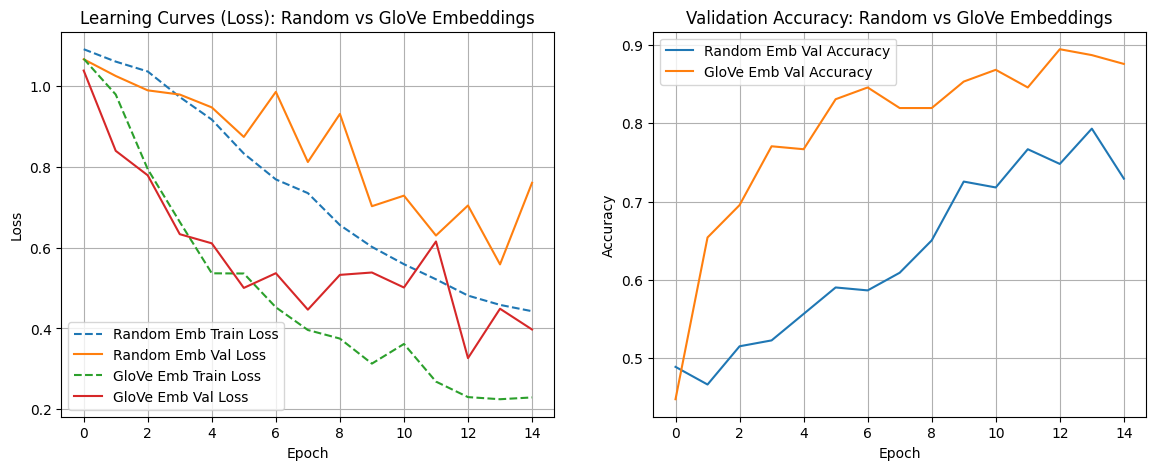

=== Звіт класифікації BiLSTM + GloVe (Test) ===
               precision    recall  f1-score   support

comp.graphics     0.7583    0.8792    0.8143       389
    sci.crypt     0.8135    0.7601    0.7859       396
    sci.space     0.8715    0.7919    0.8298       394

     accuracy                         0.8100      1179
    macro avg     0.8144    0.8104    0.8100      1179
 weighted avg     0.8147    0.8100    0.8099      1179

                    Модель  Test Accuracy  Test F1-score  Час навчання (сек)
BiLSTM (Random Embeddings)       0.703138       0.703737                 5.5
 BiLSTM (Pretrained GloVe)       0.810008       0.809932                 4.8


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(hist_txt_rand['train_loss'], '--', label='Random Emb Train Loss')
ax[0].plot(hist_txt_rand['val_loss'], label='Random Emb Val Loss')
ax[0].plot(hist_txt_glove['train_loss'], '--', label='GloVe Emb Train Loss')
ax[0].plot(hist_txt_glove['val_loss'], label='GloVe Emb Val Loss')
ax[0].set_title('Learning Curves (Loss): Random vs GloVe Embeddings')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(hist_txt_rand['val_acc'], label='Random Emb Val Accuracy')
ax[1].plot(hist_txt_glove['val_acc'], label='GloVe Emb Val Accuracy')
ax[1].set_title('Validation Accuracy: Random vs GloVe Embeddings')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].legend()
ax[1].grid(True)
plt.show()

def evaluate_txt_model(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for x_b, y_b in loader:
            x_b = x_b.to(device)
            preds.extend(model(x_b).argmax(1).cpu().numpy())
            targets.extend(y_b.numpy())
    return accuracy_score(targets, preds), f1_score(targets, preds, average='weighted'), preds

acc_rand, f1_rand, _ = evaluate_txt_model(lstm_random, test_txt_loader)
acc_glove, f1_glove, preds_glove = evaluate_txt_model(lstm_glove, test_txt_loader)

print("=== Звіт класифікації BiLSTM + GloVe (Test) ===")
print(classification_report(y_txt_test, preds_glove, target_names=categories, digits=4))

comparison_df3 = pd.DataFrame({
    'Модель': ['BiLSTM (Random Embeddings)', 'BiLSTM (Pretrained GloVe)'],
    'Test Accuracy': [acc_rand, acc_glove],
    'Test F1-score': [f1_rand, f1_glove],
    'Час навчання (сек)': [round(time_txt_rand, 1), round(time_txt_glove, 1)]
})
print(comparison_df3.to_string(index=False))

Використання готових векторних представлень слів GloVe (100d) (покриття словника склало 87.8% — 13 177 із 15 000 слів) підвищило точність класифікації трьох категорій (comp.graphics, sci.crypt, sci.space) на тестовій вибірці на +10.69%

На графіках Learning Curves видно, що модель із GloVe збігається значно швидше. На 3-й епосі вона має Val Accuracy = 69.55% (рівень, якого модель із випадковою ініціалізацією досягає на 12–15 епохах). У моделі з Random Embeddings наприкінці навчання (12–15 епохи) спостерігається стрибок Val Loss вгору (0.6297 → 0.7600) при падінні Train Loss (0.5214 → 0.4425), що вказує на сильніше перенавчання на малій вибірці (1 506 тренувальних текстів)

Оскільки тренувальна вибірка текстів невелика (1 506 документів), випадково ініціалізований Embedding layer не встигає вивчити семантичні зв'язки між рідкісними термінами. Попередньо навчені вектори GloVe привносять зовнішні семантичні знання про близькість слів, що суттєво покращує узагальнювальну здатність моделі на нових даних